In [1]:
import base
import os    
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook as tqdm
import torch

from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import problem2
import optimiser_problem2_new_new as optimiser_problem2
from math import factorial
import pickle

C:\Users\User\anaconda3\Lib\site-packages\torch\__init__.py:1275: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\tensor\python_tensor.cpp:436.)
  _C._set_default_tensor_type(t)


In [2]:
sigma_s = 1e-1
b1 = 1e-3
b3 = 0
sigma2 = 1

params = {'b0': 1, 'b1': b1, 'b2': 1, 'b3': b3,
          'sigma0': 1, 'sigma2': sigma2, 'k': 1e-3, 
          'theta1': 10, 'theta2': 1e-2, 'S0': 100, 'Q0': 10, 'X0': 0, 
          'T': 0.10, 'Nt': 1_000}

env = problem2.environment(**params)

In [3]:
np.random.seed(456)
dim = 2
order = 6

with open('W_sig_1.pkl', 'rb') as f:
    W_sig = pickle.load(f)
    f.close()

# with open('F_optimised_problem2.pkl', 'rb') as f:
#     F = pickle.load(f)
#     f.close()
    
#env = problem2.environment(**params)
optimiser_1 = optimiser_problem2.Optimiser(env, W_sig, order = order)
# F = ta.sig_to_tensor(F, optimiser_1.dim, optimiser_1.order)
# optimiser_1.F = F

In [4]:
np.random.seed(456)
trunc_lev = 4
trunc_lev_1 = 4
n_epochs = 2
lr = 5

optimiser_1.train_sgd(n_epochs, lr = lr, trunc_lev_s = trunc_lev, method='SGD')

F = optimiser_1.F

strag_sig = problem2.sig_strag_dot(F, order = order)

C:\Users\User\Documents\GitHub\optimal-control-with-signatures\notebooks\../src\tensor_algebra.py:191: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  l = np.sqrt(float(self.dot(self)))
[1080.28663999]: 100%|██████████| 2/2 [00:21<00:00, 10.91s/it]


In [5]:
# # F = optimiser_1.F

# # strag_sig = problem2.sig_strag_dot(F, order = order)

# with open('F_optimised_problem2.pkl', 'wb') as f:
#     pickle.dump(F.flatten(), f)
#     f.close()

In [6]:
np.random.seed(123)

nsims = 2

env.simulate(nsims, strag_sig, order)

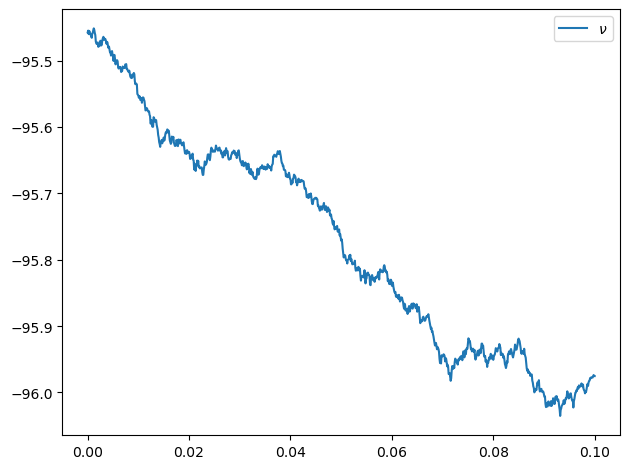

In [7]:
nsim = 1

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$')
#plt.plot(env_baseline.timesteps, env_baseline.nu[:,nsim], label=r'$\nu (HJB)$')
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
print(f'Performance criterion\nSig: {env.run_crit[-1,:].mean()}')
print(f'Wealth\nSig: {env.wealth[-1,:].mean()}')

Performance criterion
Sig: 1073.9694510583356
Wealth
Sig: 947.7742624500729


In [9]:
optimiser_1.value_fn(F.flatten(), trunc_lev_s = trunc_lev)

-1080.306777072088

In [14]:
# f_s_sig = problem1.sig_strag_dot_1(f_s, order = trunc_lev)
# f_alpha_sig = problem1.sig_strag_dot_1(f_alpha, order = trunc_lev_1)
# f_perf_crit = problem1.sig_strag_dot_1(p_perf, order = order)

nsim = 1

LF = optimiser_1.LF
p_perf = optimiser_1.p_perf

f_s_sig = problem2.sig_strag_dot_2(LF, order = trunc_lev)
f_perf_crit = problem2.sig_strag_dot_2(p_perf, order = order)

S_sig = np.zeros((env.Nt+1,))
perf_hist = np.zeros((env.Nt+1,))

W_sig = np.zeros(((env.dim**(order+1) - env.dim)//(env.dim - 1),))

S_sig[0] = f_s_sig(env,W_sig,dim,0)
perf_hist[0] = f_perf_crit(env,W_sig,dim,0)

# S_sig = f_s_sig(env)
# alpha_hat_sig = f_alpha_sig(env)
# perf_hist = f_perf_crit(env)

for it in range(1,env.Nt+1):
    path_increment = np.array([env.timesteps[it]-env.timesteps[it-1], env.W[it,nsim]-env.W[it-1,nsim]])
    W_sig[:] = iisignature.sigjoin(W_sig[:], path_increment, order)
    S_sig[it] = f_s_sig(env,W_sig,dim,it)
    perf_hist[it] = f_perf_crit(env,W_sig,dim,it)
    #S_sig[it,:] = strag_sig(env,it)

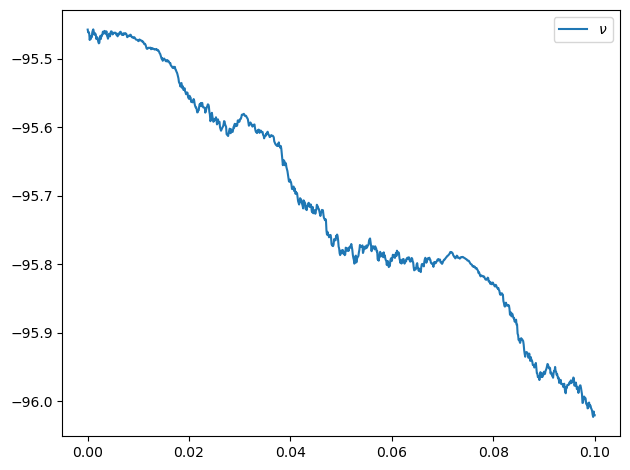

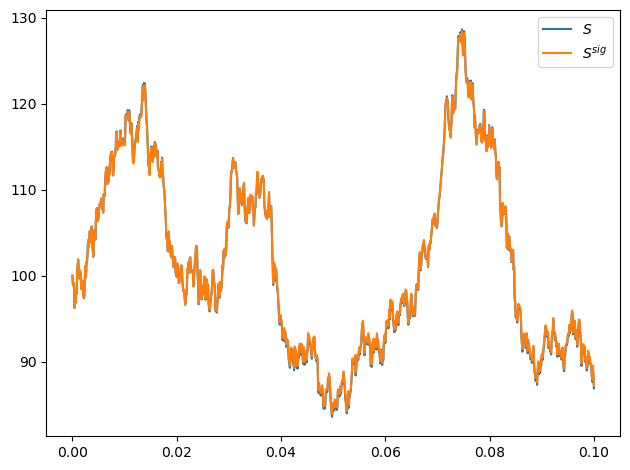

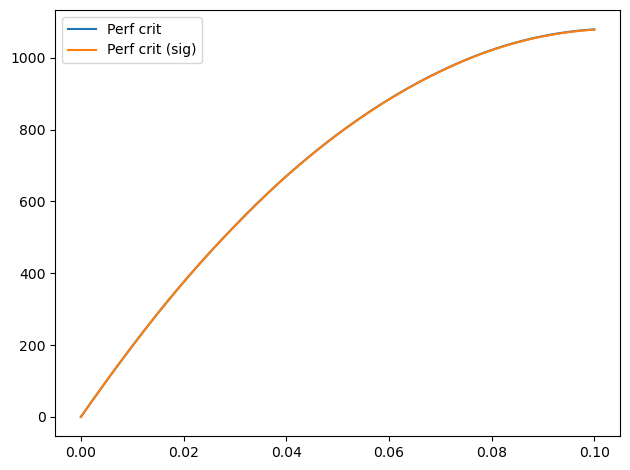

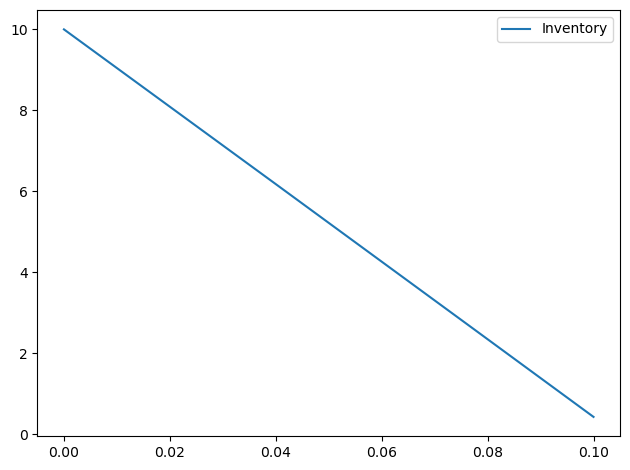

In [16]:
nsim = 0

LF = optimiser_1.LF
p_perf = optimiser_1.p_perf

f_s_sig = problem2.sig_strag_dot_2(LF, order = trunc_lev)
f_perf_crit = problem2.sig_strag_dot_2(p_perf, order = order)

S_sig = np.zeros((env.Nt+1,))
perf_hist = np.zeros((env.Nt+1,))

W_sig = np.zeros(((env.dim**(order+1) - env.dim)//(env.dim - 1),))

S_sig[0] = f_s_sig(env,W_sig,dim,0)
perf_hist[0] = f_perf_crit(env,W_sig,dim,0)

# S_sig = f_s_sig(env)
# alpha_hat_sig = f_alpha_sig(env)
# perf_hist = f_perf_crit(env)

for it in range(1,env.Nt+1):
    path_increment = np.array([env.timesteps[it]-env.timesteps[it-1], env.W[it,nsim]-env.W[it-1,nsim]])
    W_sig[:] = iisignature.sigjoin(W_sig[:], path_increment, order)
    S_sig[it] = f_s_sig(env,W_sig,dim,it)
    perf_hist[it] = f_perf_crit(env,W_sig,dim,it)
    #S_sig[it,:] = strag_sig(env,it)

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.S[:,nsim], label=r'$S$')
plt.plot(env.timesteps, S_sig[:], label=r'$S^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps[:], env.run_crit[:,nsim], label=r'Perf crit')
plt.plot(env.timesteps[:], perf_hist[:], label=r'Perf crit (sig)')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps[:], env.Q[:,nsim], label=r'Inventory')
plt.legend()
plt.tight_layout()
plt.show()